# Fake News Detection




In [ ]:
import pandas as pd
import matplotlib.pyplot as plot
import re
from collections import Counter

In [ ]:
df = pd.read_csv("WELFake_Dataset.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print()
df.info()
df.head()


Shape: (72134, 4)
Columns: ['Unnamed: 0', 'title', 'text', 'label']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


## Label distribution


In [ ]:
print(df["label"].value_counts())
print()
print((df["label"].value_counts(normalize=True) * 100).round(2))


label
1    37106
0    35028
Name: count, dtype: int64

label
1    51.44
0    48.56
Name: proportion, dtype: float64


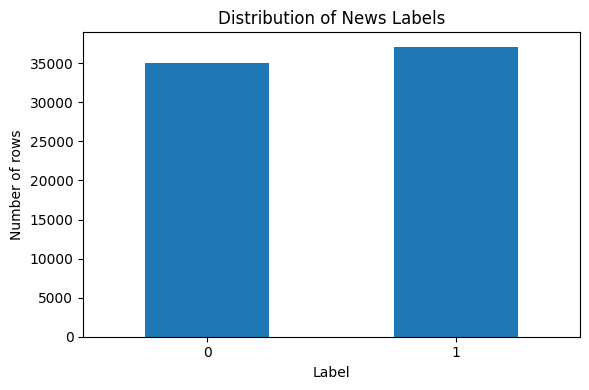

In [ ]:

df["label"].value_counts().sort_index().plot(kind="bar", figsize=(6, 4))
plot.xlabel("Label")
plot.ylabel("Number of rows")
plot.title("Distribution of News Labels")
plot.xticks(rotation=0)
plot.tight_layout()
plot.show()


## Missing values


In [ ]:
print(df.isnull().sum())


Unnamed: 0      0
title         558
text           39
label           0
dtype: int64


In [ ]:
df[df["title"].isnull()][["title", "text", "label"]].head()


,title,text,label
1,NaN,Did they post their votes for Hillary already?,1
43,NaN,True. Hillary needs a distraction and what bet...,1
162,NaN,All eyes on Electoral delegates. The People kn...,1
185,NaN,Cool,1
269,NaN,A leading US senator: US Supporting War in Syr...,1


In [ ]:
df[df["text"].isnull()][["title", "text", "label"]].head()


,title,text,label
2457,Après le succès de « Mariés au premier regard ...,NaN,1
3534,Elections US : les premières estimations donne...,NaN,1
3709,110% des Américains assurent qu’ils continuero...,NaN,1
5612,Des millions d’Américains recherchent massivem...,NaN,1
6270,Vladimir Poutine est élu 45e Président des Eta...,NaN,1


##  Duplicate checks

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated title occurrences:", df.duplicated(subset="title").sum())
print("Repeated text occurrences:", df.duplicated(subset="text").sum())
print("Repeated title-text pair occurrences:", df.duplicated(subset=["title", "text"]).sum())


Exact duplicate rows: 0
Repeated title occurrences: 9786
Repeated text occurrences: 9415
Repeated title-text pair occurrences: 8456


In [ ]:
duplicate_titles = df[df.duplicated(subset="title", keep=False)].sort_values("title")
duplicate_titles[["title", "text", "label"]].head(10)


,title,text,label
47584,McConnell Says He’ll Obstruct ANY Effort To H...,Siding with Trump s Attorney General Jeff Sess...,1
38487,McConnell Says He’ll Obstruct ANY Effort To H...,Siding with Trump s Attorney General Jeff Sess...,1
40330,"""Top Five Clinton Donors Are Jewish"" - How Ant...","""Top Five Clinton Donors Are Jewish"" - How Ant...",1
34585,"""Top Five Clinton Donors Are Jewish"" - How Ant...","""Top Five Clinton Donors Are Jewish"" - How Ant...",1
58423,"""Top Five Clinton Donors Are Jewish"" - How Ant...","""Top Five Clinton Donors Are Jewish"" - How Ant...",1
15085,#2816: Clinton Pride’s 8(a) Pig Farm Bridge – ...,United States Marine Field McConnell Plum Cit...,1
22321,#2816: Clinton Pride’s 8(a) Pig Farm Bridge – ...,United States Marine Field McConnell Plum Cit...,1
1946,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...,Hillary may find out she needs more than black...,1
22104,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...,Hillary may find out she needs more than black...,1
44689,#Austin: Fights Break Out Between Police and S...,Commies carrying flags fought with the Austin ...,1


In [ ]:
duplicate_texts = df[df.duplicated(subset="text", keep=False)].sort_values("text")
duplicate_texts[["title", "text", "label"]].head(10)


,title,text,label
28733,Hillary Is 70 Days Away From Controlling All F...,"\n\n \nIf Clinton is elected, Obama will hand ...",1
33501,Hillary Is 70 Days Away From Controlling All F...,"\n\n \nIf Clinton is elected, Obama will hand ...",1
16419,Just Another Day In the Life of the Clinton Cr...,"\n\n \nIn the past 24 hours, some very stunnin...",1
24633,Just Another Day In the Life of the Clinton Cr...,"\n\n \nIn the past 24 hours, some very stunnin...",1
12670,"14 Days to Do 14 Things, If You Want to Surviv...",\n\n \nUPDATE: HILLARY CLINTON IS AGAIN UNDER ...,1
1276,"14 Days to Do 14 Things, If Hillary’s Indicted...",\n\n \nUPDATE: HILLARY CLINTON IS AGAIN UNDER ...,1
20004,"14 Days to Do 14 Things, If Hillary’s Indicted...",\n\n \nUPDATE: HILLARY CLINTON IS AGAIN UNDER ...,1
24596,"CNN Fired Donna Brazile 2 Weeks Ago, Made It P...",\n\nCNN finally made it public that they have ...,1
28343,"CNN Fired Donna Brazile 2 Weeks Ago, Made It P...",\n\nCNN finally made it public that they have ...,1
23436,"Project Veritas Video 4 - 20K Bribery to DNC, ...",\n\nIn the effort to prove the credibility of ...,1


In [ ]:
# Check whether identical title-text pairs are associated with more than one label.
pair_label_counts = df.groupby(["title", "text"], dropna=False)["label"].nunique()
print("Title-text groups with conflicting labels:", (pair_label_counts > 1).sum())


Title-text groups with conflicting labels: 0


##  Headline and article length


In [ ]:
title_len = df["title"].str.split().str.len()
text_len = df["text"].str.split().str.len()

print("Headline word-count summary:")
print(title_len.describe())
print()
print("Article word-count summary:")
print(text_len.describe())


Headline word-count summary:
count    71576.000000
mean        12.268218
std          4.133661
min          1.000000
25%          9.000000
50%         12.000000
75%         14.000000
max         72.000000
Name: title, dtype: float64

Article word-count summary:
count    72095.000000
mean       540.843346
std        625.442464
min          0.000000
25%        227.000000
50%        399.000000
75%        667.000000
max      24234.000000
Name: text, dtype: float64


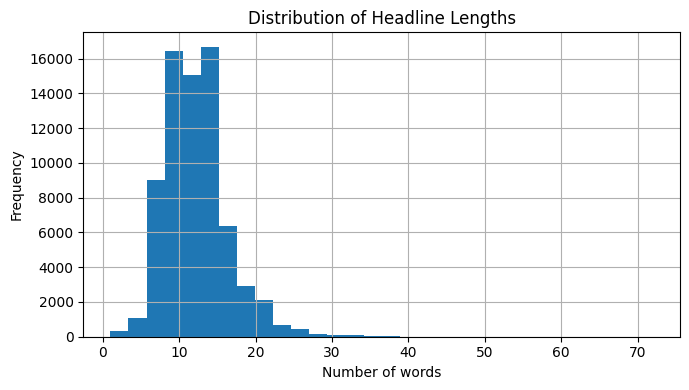

In [ ]:
title_len.hist(bins=30, figsize=(7, 4))
plot.xlabel("Number of words")
plot.ylabel("Frequency")
plot.title("Distribution of Headline Lengths")
plot.tight_layout()
plot.show()


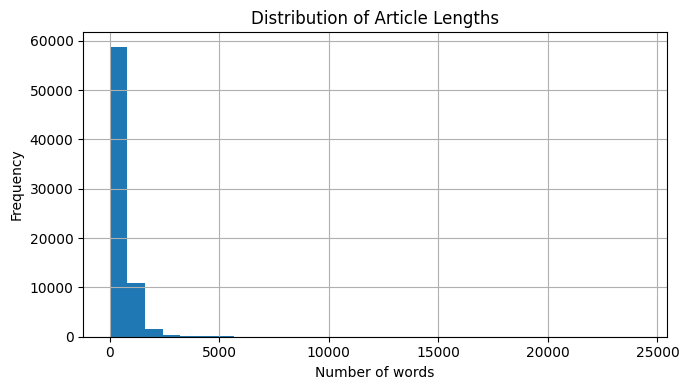

In [ ]:
text_len.hist(bins=30, figsize=(7, 4))
plot.xlabel("Number of words")
plot.ylabel("Frequency")
plot.title("Distribution of Article Lengths")
plot.tight_layout()
plot.show()


## Compare text length by label


In [ ]:
df["title_len"] = title_len
df["text_len"] = text_len

print(df.groupby("label")[["title_len", "text_len"]].median())


       title_len  text_len
label                     
0           11.0     427.0
1           13.0     369.0


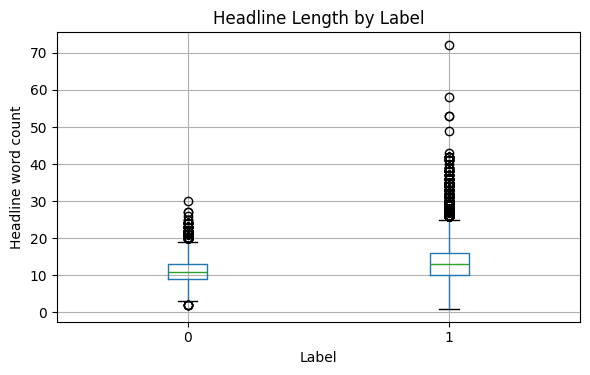

In [ ]:
df.boxplot(column="title_len", by="label", figsize=(6, 4))
plot.xlabel("Label")
plot.ylabel("Headline word count")
plot.title("Headline Length by Label")
plot.suptitle("")
plot.tight_layout()
plot.show()


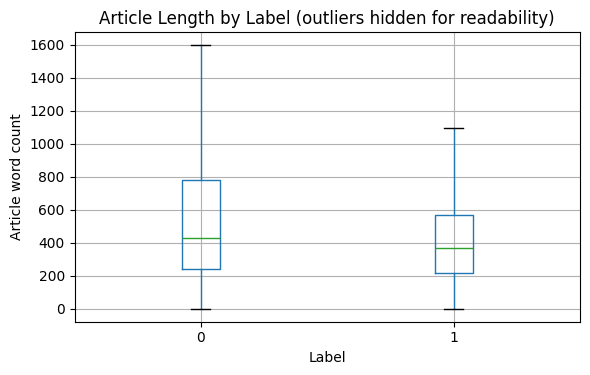

In [ ]:
# Article lengths can be very skewed, so this box plot may contain many outliers.
df.boxplot(column="text_len", by="label", showfliers=False, figsize=(6, 4))
plot.xlabel("Label")
plot.ylabel("Article word count")
plot.title("Article Length by Label (outliers hidden for readability)")
plot.suptitle("")
plot.tight_layout()
plot.show()


##  Frequent words by label



In [ ]:
def common_words(text_series, number=15):
    words = []
    for article in text_series.dropna():
        article = article.lower()
        words.extend(re.findall(r"\b[a-z]{2,}\b", article))
    return Counter(words).most_common(number)

for label_value in sorted(df["label"].dropna().unique()):
    print("\nMost common words for label", label_value)
    print(common_words(df.loc[df["label"] == label_value, "text"], 15))



Most common words for label 0
[('the', 1185992), ('to', 573313), ('of', 514486), ('and', 465218), ('in', 430776), ('that', 259158), ('on', 216509), ('for', 193669), ('said', 184607), ('is', 158734), ('he', 154999), ('it', 142785), ('with', 133629), ('was', 132623), ('as', 122066)]

Most common words for label 1
[('the', 1056116), ('to', 532036), ('of', 477833), ('and', 449219), ('in', 333408), ('that', 272567), ('is', 220433), ('for', 171817), ('it', 155771), ('on', 147962), ('with', 118306), ('as', 115256), ('he', 114224), ('was', 112608), ('this', 109853)]
